### Name: Riya Waghmare
### Class: B-B3
### Roll No:35

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score,precision_score,recall_score,confusion_matrix,classification_report,ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings("ignore")

In [ ]:
df=pd.read_csv("ai4i2020.csv")

In [ ]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [ ]:
df.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [ ]:
df.shape

(10000, 14)

In [ ]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
df.columns

Index(['UDI', 'Product ID', 'Type', 'Air temperature [K]',
       'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]',
       'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF',
       'RNF'],
      dtype='object')

In [ ]:
df.dtypes

,0
UDI,int64
Product ID,object
Type,object
Air temperature [K],float64
Process temperature [K],float64
Rotational speed [rpm],int64
Torque [Nm],float64
Tool wear [min],int64
Machine failure,int64
TWF,int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9996,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9997,False,False,False,False,False,False,False,False,False,False,False,False,False,False
9998,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [ ]:
df.isnull().sum()

,0
UDI,0
Product ID,0
Type,0
Air temperature [K],0
Process temperature [K],0
Rotational speed [rpm],0
Torque [Nm],0
Tool wear [min],0
Machine failure,0
TWF,0


In [ ]:
y=df["Machine failure"]

In [ ]:
X=df[
    ["Type","Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]
]

In [ ]:
print(X.shape)
print(y.shape)

(10000, 6)
(10000,)


In [ ]:
categorical_features=["Type"]
numerical_features=[
    "Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"
]

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print("Training samples:",X_train.shape[0])
print("Testing samples:",X_test.shape[0])

Training samples: 8000
Testing samples: 2000


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [ ]:
linear_svm=Pipeline(
    steps=[("preprocessor",preprocessor),("classifier",SVC(kernel="linear"))]
)
linear_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC(kernel='linear'))])

In [ ]:
y_pred_linear=linear_svm.predict(X_test)

In [ ]:


accuracy_linear = accuracy_score(y_test, y_pred_linear)
precision_linear = precision_score(y_test, y_pred_linear, zero_division=0)
recall_linear = recall_score(y_test, y_pred_linear, zero_division=0)
f1_linear = f1_score(y_test, y_pred_linear, zero_division=0)

print("Accuracy:", accuracy_linear)
print("Precision:", precision_linear)
print("Recall:", recall_linear)
print("F1 Score:", f1_linear)

Accuracy: 0.966
Precision: 0.0
Recall: 0.0
F1 Score: 0.0


In [ ]:
print(
    classification_report(y_test,y_pred_linear,target_names=["No Failure","Failure"],zero_division=0)
)

              precision    recall  f1-score   support

  No Failure       0.97      1.00      0.98      1932
     Failure       0.00      0.00      0.00        68

    accuracy                           0.97      2000
   macro avg       0.48      0.50      0.49      2000
weighted avg       0.93      0.97      0.95      2000



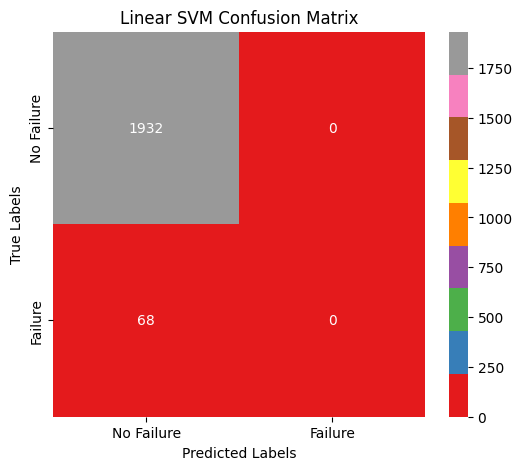

In [ ]:
cm_linear=confusion_matrix(y_test,y_pred_linear)
plt.figure(figsize=(6,5))
sns.heatmap(cm_linear,annot=True,fmt="d",cmap="Set1",
             xticklabels=["No Failure","Failure"],yticklabels=["No Failure","Failure"])
plt.title("Linear SVM Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [ ]:
rbf_svm=Pipeline(
    steps=[("preprocessor",preprocessor),("classifier",SVC(kernel="rbf"))]
)
rbf_svm.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Air temperature [K]',
                                                   'Process temperature [K]',
                                                   'Rotational speed [rpm]',
                                                   'Torque [Nm]',
                                                   'Tool wear [min]']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Type'])])),
                ('classifier', SVC())])

In [ ]:
y_pred_rbf=rbf_svm.predict(X_test)

In [ ]:

accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
precision_rbf = precision_score(y_test,y_pred_rbf, zero_division=0)
recall_rbf = recall_score(y_test,y_pred_rbf, zero_division=0)
f1_rbf = f1_score(y_test,y_pred_rbf, zero_division=0)

print("Accuracy:", accuracy_rbf)
print("Precision:", precision_rbf)
print("Recall:", recall_rbf)
print("F1 Score:", f1_rbf)

Accuracy: 0.972
Precision: 0.875
Recall: 0.20588235294117646
F1 Score: 0.3333333333333333


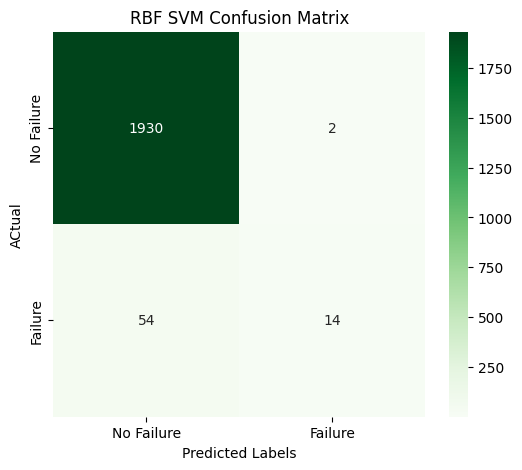

In [ ]:
cm_linear=confusion_matrix(y_test,y_pred_rbf)
plt.figure(figsize=(6,5))
sns.heatmap(cm_linear,annot=True,fmt="d",cmap="Greens",
             xticklabels=["No Failure","Failure"],yticklabels=["No Failure","Failure"])
plt.title("RBF SVM Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("ACtual")
plt.show()

In [ ]:
comparison=pd.DataFrame({
    "Kernel":["Linear","RBF"],
    "Accuracy":[accuracy_linear,accuracy_rbf],
    "Precision":[precision_linear,precision_rbf],
    "Recall":[recall_linear,recall_rbf],
    "F1 Score":[f1_linear,f1_rbf]
})
comparison

,Kernel,Accuracy,Precision,Recall,F1 Score
0,Linear,0.966,0.000,0.000000,0.000000
1,RBF,0.972,0.875,0.205882,0.333333


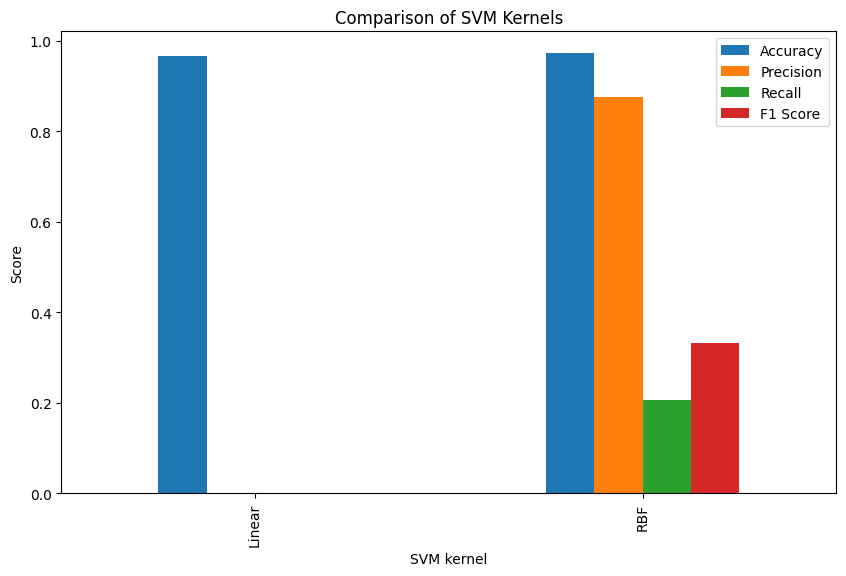

In [ ]:
comparision_plot=comparison.set_index("Kernel")
comparision_plot.plot(kind="bar",figsize=(10,6))
plt.title("Comparison of SVM Kernels")
plt.xlabel("SVM kernel")
plt.ylabel("Score")
plt.show()

In [ ]:
from sklearn.pipeline import Pipeline
pipeline=Pipeline(
    steps=[("preprocessor",preprocessor),("classifier",SVC())]
)

In [ ]:
param_grid=[{"classifier_kernel":["linear"],"classifier_C":[0.1,1,10,100]},
             {"classifier_kernel":["rbf"],"classifier_C":[0.1,1,10,100],"classifier_gamma":["scale",0.01,0.1,1]}]

In [ ]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=1,
    verbose=1
)

In [ ]:
param_grid = {
    "classifier__C": [1, 10],
    "classifier__kernel": ["linear", "rbf"]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=3,
    scoring="f1",
    n_jobs=-1,
    verbose=2,
    refit=True,
    error_score="raise"
)

grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 4 candidates, totalling 12 fits


GridSearchCV(cv=3, error_score='raise',
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         StandardScaler(),
                                                                         ['Air '
                                                                          'temperature '
                                                                          '[K]',
                                                                          'Process '
                                                                          'temperature '
                                                                          '[K]',
                                                                          'Rotational '
                                                                          'speed '
                                                                          '[rpm]',
                                                                          'Torque '
                                                                          '[Nm]',
                                                                          'Tool '
                                                                          'wear '
                                                                          '[min]']),
                                                                        ('cat',
                                                                         OneHotEncoder(handle_unknown='ignore'),
                                                                         ['Type'])])),
                                       ('classifier', SVC())]),
             n_jobs=-1,
             param_grid={'classifier__C': [1, 10],
                         'classifier__kernel': ['linear', 'rbf']},
             scoring='f1', verbose=2)

In [ ]:
print("GridSearch CV Complete")
print("Best Parameters:", grid_search.best_params_)
print("Best Cross Validation F1 Score:", grid_search.best_score_)

GridSearch CV Complete
Best Parameters: {'classifier__C': 10, 'classifier__kernel': 'rbf'}
Best Cross Validation F1 Score: 0.6324307656407564


In [ ]:
y_pred_tuned = grid_search.predict(X_test)

accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
precision_tuned = precision_score(y_test, y_pred_tuned, zero_division=0)
recall_tuned = recall_score(y_test, y_pred_tuned, zero_division=0)
f1_tuned = f1_score(y_test, y_pred_tuned, zero_division=0)

        Model  Accuracy  Precision  Recall  F1 Score
0  Linear SVM     0.966     0.0000  0.0000    0.0000
1     RBF SVM     0.972     0.8750  0.2059    0.3333
2   Tuned SVM     0.979     0.7708  0.5441    0.6379


In [ ]:
final_comaprision = pd.DataFrame({
    "Model": ["Linear SVM", "RBF SVM", "Tuned SVM"],
    "Accuracy": [accuracy_linear, accuracy_rbf, accuracy_tuned],
    "Precision": [precision_linear, precision_rbf, precision_tuned],
    "Recall": [recall_linear, recall_rbf, recall_tuned],
    "F1 Score": [f1_linear, f1_rbf, f1_tuned]
})

print(final_comaprision)

        Model  Accuracy  Precision    Recall  F1 Score
0  Linear SVM     0.966   0.000000  0.000000  0.000000
1     RBF SVM     0.972   0.875000  0.205882  0.333333
2   Tuned SVM     0.979   0.770833  0.544118  0.637931
